# 1. Environment Setup & Data Loading

In [63]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

# os.environ["PATH"] = os.environ.get("XILINX_VITIS", "") + "/bin:" + os.environ.get("PATH", "")

# 2. Prepare MNIST Dataset
Load MNIST dataset and preprocess it for training and evaluation.

In [64]:
def preprocess(image, label, nclasses=10):
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.expand_dims(image, axis=-1)
    label = tf.one_hot(tf.squeeze(label), nclasses)
    return image, label

with tf.device("/CPU:0"):
    ds_train, info = tfds.load("mnist", split="train[:90%]", with_info=True, as_supervised=True)
    ds_val = tfds.load("mnist", split="train[-10%:]", shuffle_files=True, as_supervised=True)
    
    n_classes = info.features["label"].num_classes
    input_shape = info.features["image"].shape
    batch_size = 1024
    
    train_data = ds_train.map(lambda img, lbl: preprocess(img, lbl, n_classes))
    train_data = train_data.shuffle(4096).batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)
    
    val_data = ds_val.map(lambda img, lbl: preprocess(img, lbl, n_classes)).batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)
    
    X_test, Y_test = tfds.as_numpy(tfds.load("mnist", split="test", batch_size=-1, as_supervised=True))
    X_test, Y_test = preprocess(X_test, Y_test, nclasses=n_classes)
    X_test, Y_test = np.array(X_test), np.array(Y_test)
    
    train_size = int(info.splits["train"].num_examples)

# 3. Sparsity (Pruning) Exploration
Before applying quantization, we evaluate the baseline floating-point model at different sparsity levels to find the optimal pruning percentage.

In [65]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, BatchNormalization, Conv2D, MaxPooling2D, Activation, Flatten, Dense
from tensorflow.keras.regularizers import l1
from tensorflow.keras.models import Model
import tensorflow_model_optimization as tfmot
from tensorflow_model_optimization.sparsity import keras as sparsity

def build_baseline_model(input_shape, n_classes):
    x = x_in = Input(shape=input_shape)
    
    x = Conv2D(16, kernel_size=(3, 3), strides=(1, 1), kernel_initializer='lecun_uniform', kernel_regularizer=l1(0.0001), use_bias=True, name="conv_0")(x)
    x = BatchNormalization(name="bn_conv_0")(x)
    x = Activation("relu", name="act_0")(x)
    x = MaxPooling2D(pool_size=(2, 2), name="pool_0")(x)
    
    x = Conv2D(16, kernel_size=(3, 3), strides=(1, 1), kernel_initializer='lecun_uniform', kernel_regularizer=l1(0.0001), use_bias=True, name="conv_1")(x)
    x = BatchNormalization(name="bn_conv_1")(x)
    x = Activation("relu", name="act_1")(x)
    x = MaxPooling2D(pool_size=(2, 2), name="pool_1")(x)
    
    x = Conv2D(24, kernel_size=(3, 3), strides=(1, 1), kernel_initializer='lecun_uniform', kernel_regularizer=l1(0.0001), use_bias=True, name="conv_2")(x)
    x = BatchNormalization(name="bn_conv_2")(x)
    x = Activation("relu", name="act_2")(x)
    x = MaxPooling2D(pool_size=(2, 2), name="pool_2")(x)
    
    x = Flatten()(x)
    
    x = Dense(42, kernel_initializer='lecun_uniform', kernel_regularizer=l1(0.0001), use_bias=False, name="dense_0")(x)
    x = BatchNormalization(name="bn_dense_0")(x)
    x = Activation("relu", name="act_dense_0")(x)
    
    x = Dense(64, kernel_initializer='lecun_uniform', kernel_regularizer=l1(0.0001), use_bias=False, name="dense_1")(x)
    x = BatchNormalization(name="bn_dense_1")(x)
    x = Activation("relu", name="act_dense_1")(x)
    
    x = Dense(int(n_classes), name="output_dense")(x)
    x_out = Activation("linear", name="output_activation")(x)
    
    return Model(inputs=[x_in], outputs=[x_out], name="baseline_model")

Skipping Sparsity Exploration training. Loading scores from disk...

--- Loaded Sparsity Accuracies and Models ---
0% Sparsity Test Accuracy: 0.9799
50% Sparsity Test Accuracy: 0.9744
70% Sparsity Test Accuracy: 0.9710
90% Sparsity Test Accuracy: 0.9513


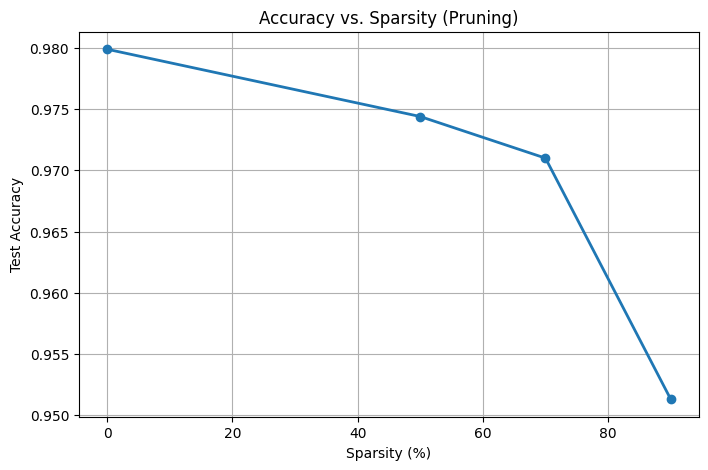

In [66]:
TRAIN = False
NSTEPS = int(train_size * 0.9) // batch_size
n_epochs = 15

sparsity_levels = [0.0, 0.50, 0.70, 0.90]
sparsity_scores = {}
baseline_models = {}
if os.path.exists("saved_models/sparsity_scores.npy"):
    sparsity_scores = np.load("saved_models/sparsity_scores.npy", allow_pickle=True).item()

if TRAIN:
    for s in sparsity_levels:
        model_path = f"saved_models/baseline_{int(s*100)}sparse.h5"
        if s in sparsity_scores and os.path.exists(model_path):
            print(f"[*] Skipping {int(s*100)}% Sparsity: Already trained. Score: {sparsity_scores[s]:.4f}")
            with tfmot.sparsity.keras.prune_scope():
                baseline_models[s] = tf.keras.models.load_model(model_path)
            continue
            
        print(f"\n{'='*40}\nTraining Baseline Model with {int(s*100)}% Sparsity\n{'='*40}")
        model = build_baseline_model(input_shape, n_classes)
        
        def pruneFunction(layer):
            pruning_params = {
                "pruning_schedule": sparsity.PolynomialDecay(
                    initial_sparsity=0.0, final_sparsity=s, 
                    begin_step=NSTEPS * 2, end_step=NSTEPS * (n_epochs - 2), frequency=NSTEPS
                )
            }
            if isinstance(layer, (Conv2D, Dense)) and layer.name != "output_dense":
                return tfmot.sparsity.keras.prune_low_magnitude(layer, **pruning_params)
            return layer
    
        if s > 0:
            pruned_model = tf.keras.models.clone_model(model, clone_function=pruneFunction)
        else:
            pruned_model = model
            
        LOSS = tf.keras.losses.CategoricalCrossentropy(from_logits=True)
        OPTIMIZER = tf.keras.optimizers.Adam(learning_rate=3e-3)
        pruned_model.compile(loss=LOSS, optimizer=OPTIMIZER, metrics=["accuracy"])
        
        callbacks = [tf.keras.callbacks.EarlyStopping(patience=10, verbose=1, restore_best_weights=True)]
        if s > 0:
            callbacks.append(tfmot.sparsity.keras.UpdatePruningStep())
        
        pruned_model.fit(train_data, epochs=n_epochs, validation_data=val_data, callbacks=callbacks, verbose=1)
        
        score = pruned_model.evaluate(X_test, Y_test, verbose=0)
        print(f"\n{int(s*100)}% Sparsity Test Accuracy: {score[1]:.4f}")
        sparsity_scores[s] = score[1]
        
        os.makedirs("saved_models", exist_ok=True)
        pruned_model.save(f"saved_models/baseline_{int(s*100)}sparse.h5")
        baseline_models[s] = pruned_model
        np.save("saved_models/sparsity_scores.npy", sparsity_scores)
    
else:
    print("Skipping Sparsity Exploration training. Loading scores from disk...")
    if os.path.exists("saved_models/sparsity_scores.npy"):
        sparsity_scores = np.load("saved_models/sparsity_scores.npy", allow_pickle=True).item()
        print("\n--- Loaded Sparsity Accuracies and Models ---")
        for s, acc in sparsity_scores.items():
            print(f"{int(s*100)}% Sparsity Test Accuracy: {acc:.4f}")
            model_path = f"saved_models/baseline_{int(s*100)}sparse.h5"
            if os.path.exists(model_path):
                with tfmot.sparsity.keras.prune_scope():
                    baseline_models[s] = tf.keras.models.load_model(model_path)

if sparsity_scores:
    plt.figure(figsize=(8, 5))
    plt.plot([s*100 for s in sparsity_levels], list(sparsity_scores.values()), marker='o', linewidth=2)
    plt.title('Accuracy vs. Sparsity (Pruning)')
    plt.xlabel('Sparsity (%)')
    plt.ylabel('Test Accuracy')
    plt.grid(True)
    plt.show()

# 4. Design Space Exploration (DSE) Setup
We parameterize the QKeras model construction by `bit_width`.

In [67]:
from tensorflow.keras.layers import Input, BatchNormalization, Conv2D, MaxPooling2D, Activation, Flatten, Dense
from tensorflow.keras.regularizers import l1
from tensorflow.keras.models import Model
from qkeras import QActivation, QDense, QConv2DBatchnorm
import tensorflow_model_optimization as tfmot
from tensorflow_model_optimization.sparsity import keras as sparsity

def build_qkeras_model(bit_width, input_shape, n_classes):
    filters_per_conv_layer = [16, 16, 24]
    neurons_per_dense_layer = [42, 64]
    
    quantizer = f"quantized_bits({bit_width},0,alpha=1)"
    act_quantizer = f"quantized_relu({bit_width})"
    
    x = x_in = Input(shape=input_shape)
    
    for i, f in enumerate(filters_per_conv_layer):
        x = QConv2DBatchnorm(
            int(f), kernel_size=(3, 3), strides=(1, 1),
            kernel_quantizer=quantizer, bias_quantizer=quantizer,
            kernel_initializer="lecun_uniform", kernel_regularizer=l1(0.0001),
            use_bias=True, name=f"fused_convbn_{i}"
        )(x)
        x = QActivation(act_quantizer, name=f"conv_act_{i}")(x)
        x = MaxPooling2D(pool_size=(2, 2), name=f"pool_{i}")(x)
        
    x = Flatten()(x)
    
    for i, n in enumerate(neurons_per_dense_layer):
        x = QDense(
            n, kernel_quantizer=quantizer, kernel_initializer="lecun_uniform",
            kernel_regularizer=l1(0.0001), name=f"dense_{i}", use_bias=False
        )(x)
        x = BatchNormalization(name=f"bn_dense_{i}")(x)
        x = QActivation(act_quantizer, name=f"dense_act_{i}")(x)
        
    x = Dense(int(n_classes), name="output_dense")(x)
    x_out = Activation("linear", name="output_activation")(x)
    
    return Model(inputs=[x_in], outputs=[x_out], name=f"qkeras_{bit_width}bit")

# 5. Train Models across Bit-widths and Pruning
Iterate over a list of bit-widths (e.g., 4, 6, 8) and a target sparsity.

In [68]:
import os
import glob
import numpy as np
import tensorflow as tf
import tensorflow_model_optimization as tfmot
from qkeras.utils import load_qmodel

TRAIN = False

NSTEPS = int(train_size * 0.9) // batch_size
n_epochs = 15 

trained_models = {}
test_scores = {}

os.makedirs("saved_models", exist_ok=True)
if os.path.exists("saved_models/test_scores.npy"):
    test_scores = np.load("saved_models/test_scores.npy", allow_pickle=True).item()

if TRAIN:
    target_sparsities = [0.0, 0.50, 0.70, 0.90]
    bit_widths = [2, 4, 6, 8]

    for target_sparsity in target_sparsities:
        print(f"\n\n{'#'*60}")
        print(f"   CHECKING SWEEP FOR {int(target_sparsity*100)}% SPARSITY")
        print(f"{'#'*60}")
        
        for bw in bit_widths:
            dict_key = f"{bw}bit_{int(target_sparsity*100)}sparse"
            model_path = f"saved_models/{dict_key}.h5"
            
            # Check if model is already trained
            if dict_key in test_scores and os.path.exists(model_path):
                print(f"[*] Skipping {bw}-bit ({int(target_sparsity*100)}% Sparsity): Already trained. Score: {test_scores[dict_key]:.4f}")
                continue 
                
            print(f"\n{'='*40}\nTraining {bw}-bit Model ({int(target_sparsity*100)}% Sparsity)\n{'='*40}")
            model = build_qkeras_model(bw, input_shape, n_classes)
            
            # Polynomial decay pruning schedule
            def pruneFunction(layer):
                pruning_params = {
                    "pruning_schedule": sparsity.PolynomialDecay(
                        initial_sparsity=0.0, final_sparsity=target_sparsity, 
                        begin_step=NSTEPS * 2, end_step=NSTEPS * (n_epochs - 2), frequency=NSTEPS
                    )
                }
                if isinstance(layer, (QConv2DBatchnorm, QDense)) and layer.name != "output_dense":
                    return tfmot.sparsity.keras.prune_low_magnitude(layer, **pruning_params)
                return layer

            pruned_model = tf.keras.models.clone_model(model, clone_function=pruneFunction)
            
            LOSS = tf.keras.losses.CategoricalCrossentropy(from_logits=True)
            OPTIMIZER = tf.keras.optimizers.Adam(learning_rate=3e-3)
            pruned_model.compile(loss=LOSS, optimizer=OPTIMIZER, metrics=["accuracy"])
            
            callbacks = [
                tf.keras.callbacks.EarlyStopping(patience=5, verbose=1, restore_best_weights=True),
                tfmot.sparsity.keras.UpdatePruningStep(),
            ]
            
            pruned_model.fit(train_data, epochs=n_epochs, validation_data=val_data, callbacks=callbacks, verbose=1)
            
            score = pruned_model.evaluate(X_test, Y_test, verbose=0)
            print(f"\n{bw}-bit ({int(target_sparsity*100)}% Sparsity) Test Accuracy: {score[1]:.4f}")
            
            test_scores[dict_key] = score[1]
            pruned_model.save(model_path)
            np.save("saved_models/test_scores.npy", test_scores)

# Load all models into memory at the end for the next cells
print("\nLoading all trained QKeras models into memory...")
for h5_file in glob.glob("saved_models/*.h5"):
    key = os.path.basename(h5_file).replace(".h5", "")
    with tfmot.sparsity.keras.prune_scope():
        trained_models[key] = load_qmodel(h5_file, compile=False)
print("\n--- Final QKeras Accuracies ---")
for key in sorted(test_scores.keys()):
    print(f"{key}: {test_scores[key]:.4f}")



Loading all trained QKeras models into memory...


/usr/local/lib/python3.9/site-packages/keras/initializers/initializers_v2.py:120: UserWarning: The initializer LecunUniform is unseeded and being called multiple times, which will return identical values  each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initalizer instance more than once.
  warnings.warn(



--- Final QKeras Accuracies ---
2bit_0sparse: 0.8888
2bit_50sparse: 0.7460
2bit_70sparse: 0.7357
2bit_90sparse: 0.6586
4bit_0sparse: 0.9244
4bit_50sparse: 0.9173
4bit_70sparse: 0.9092
4bit_90sparse: 0.8414
6bit_0sparse: 0.9585
6bit_50sparse: 0.9523
6bit_70sparse: 0.9301
6bit_90sparse: 0.8624
8bit_0sparse: 0.9579
8bit_50sparse: 0.9580
8bit_70sparse: 0.9625
8bit_90sparse: 0.8270


# 6. Results Visualization
Plot the trade-off of accuracy vs bit-width.

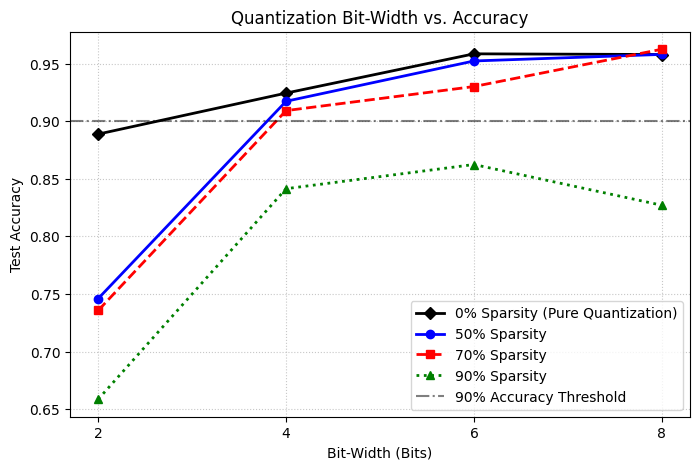

In [69]:
import matplotlib.pyplot as plt

bw_values = [2, 4, 6, 8]
acc_0 = [test_scores[f"{bw}bit_0sparse"] for bw in bw_values]
acc_50 = [test_scores[f"{bw}bit_50sparse"] for bw in bw_values]
acc_70 = [test_scores[f"{bw}bit_70sparse"] for bw in bw_values]
acc_90 = [test_scores[f"{bw}bit_90sparse"] for bw in bw_values]

plt.figure(figsize=(8, 5))

# 0% Sparsity
plt.plot(bw_values, acc_0, marker="D", linestyle="-", color="black", label="0% Sparsity (Pure Quantization)", linewidth=2)
# 50% Sparsity
plt.plot(bw_values, acc_50, marker="o", linestyle="-", color="blue", label="50% Sparsity", linewidth=2)
# 70% Sparsity 
plt.plot(bw_values, acc_70, marker="s", linestyle="--", color="red", label="70% Sparsity", linewidth=2)
# 90% Sparsity
plt.plot(bw_values, acc_90, marker="^", linestyle=":", color="green", label="90% Sparsity", linewidth=2)

# Add a dashed line showing your strict 90% Threshold!
plt.axhline(y=0.90, color='black', linestyle='-.', alpha=0.5, label="90% Accuracy Threshold")

plt.title("Quantization Bit-Width vs. Accuracy")
plt.xlabel("Bit-Width (Bits)")
plt.ylabel("Test Accuracy")
plt.xticks(bw_values) 
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend()
plt.show()

# 7. HLS Design Space Exploration (Reuse Factor)
We select the 4-bit model with 70% sparsity and generate multiple HLS projects with different `ReuseFactor` values. 
This trades off Hardware Resources (DSPs/LUTs) with Latency.

In [70]:
import os
import hls4ml

golden_model = trained_models["4bit_70sparse"]
base_model = tfmot.sparsity.keras.strip_pruning(golden_model)

reuse_factors = [1, 4, 16, 64, 256, 1024, 2048]

for rf in reuse_factors:
    output_dir = f"hls_prj_bw4_sp70_rf{rf}"

    # Protect synthesis logs if already existing
    if os.path.exists(output_dir):
        print(f"Directory {output_dir} already exists. Skipping HLS generation to protect synthesis logs.")
        continue
        
    print(f"\n{'='*40}\nGenerating HLS for ReuseFactor={rf}...\n{'='*40}")
    
    hls_config = hls4ml.utils.config_from_keras_model(base_model, granularity="name", backend="Vitis")
    
    hls_config["Model"]["ReuseFactor"] = rf
    hls_config["Model"]["Strategy"] = "Resource"
    for layer in hls_config["LayerName"].values():
        layer["ReuseFactor"] = rf
        
    hls_model = hls4ml.converters.convert_from_keras_model(
        base_model, 
        hls_config=hls_config, 
        output_dir=output_dir, 
        backend="Vitis",
        part="xcu250-figd2104-2L-e",
        io_type="io_stream"
    )
    
    # Compile the C++ code
    hls_model.compile()
    print(f"Finished generating {output_dir}")

    # =========================================================
    # UNCOMMENT TO RUN VIVADO SYNTHESIS DIRECTLY FROM JUPYTER
    # =========================================================
    # print(f"Synthesizing {output_dir}...")
    # hls_model.build(csim=False, synth=True, vsynth=False)

Directory hls_prj_bw4_sp70_rf1 already exists. Skipping HLS generation to protect synthesis logs.
Directory hls_prj_bw4_sp70_rf4 already exists. Skipping HLS generation to protect synthesis logs.
Directory hls_prj_bw4_sp70_rf16 already exists. Skipping HLS generation to protect synthesis logs.
Directory hls_prj_bw4_sp70_rf64 already exists. Skipping HLS generation to protect synthesis logs.
Directory hls_prj_bw4_sp70_rf256 already exists. Skipping HLS generation to protect synthesis logs.
Directory hls_prj_bw4_sp70_rf1024 already exists. Skipping HLS generation to protect synthesis logs.
Directory hls_prj_bw4_sp70_rf2048 already exists. Skipping HLS generation to protect synthesis logs.


# 8. Uncompressed Baseline Generation
Generate the standard 16-bit uncompressed model to see how bloated it is compared to the optimized DSE models.

In [71]:
import hls4ml

# new, uncompressed, unpruned Keras model
baseline_model = build_baseline_model(input_shape, n_classes)

output_dir = "hls_prj_baseline_uncompressed"

# Protect synthesis logs if already existing
if os.path.exists(output_dir):
    print(f"Directory {output_dir} already exists. Skipping HLS generation to protect synthesis logs.")
    
else:    
    print(f"\nGenerating HLS for the Uncompressed Baseline...")
    
    hls_config = hls4ml.utils.config_from_keras_model(baseline_model, granularity="name", backend="Vitis")
    hls_config["Model"]["ReuseFactor"] = 1
    hls_config["Model"]["Strategy"] = "Resource"
            
    hls_model = hls4ml.converters.convert_from_keras_model(
        baseline_model, 
        hls_config=hls_config, 
        output_dir=output_dir, 
        backend="Vitis",
        part="xcu250-figd2104-2L-e",
        io_type="io_stream"
    )
    
    hls_model.compile()
    print(f"Finished generating {output_dir}")

Directory hls_prj_baseline_uncompressed already exists. Skipping HLS generation to protect synthesis logs.


# 9. DSE Hardware Resource Table
Automatically parse all Vivado synthesis reports and generate the final presentation table.

In [72]:
import os
import re
import pandas as pd
from IPython.display import display

def parse_vivado_report(filepath):
    if not os.path.exists(filepath): return None
    with open(filepath, 'r') as f: content = f.read()
    
    latency_match = re.search(r'\|\s*(\d+)\|\s*(\d+)\|\s*([\d\.]+ \w+)\|\s*([\d\.]+ \w+)\|', content)
    util_match = re.search(r'\|Total\s*\|\s*(\d+)\|\s*(\d+)\|\s*(\d+)\|\s*(\d+)\|\s*\d+\|', content)
    
    if latency_match and util_match:
        return {
            "Latency (Cycles)": int(latency_match.group(2)),
            "Latency (Time)": latency_match.group(4),
            "DSPs": int(util_match.group(2)),
            "LUTs": int(util_match.group(4)),
            "FFs": int(util_match.group(3)),
            "BRAM": int(util_match.group(1))
        }
    return None

# Hardcode the exact order and pretty names you want!
report_mapping = [
    ("reports/baseline_uncompressed_rf1.rpt", "Baseline (16-bit, 0% Sparse, rf=1)"),
    ("reports/bw4_sp70_rf1.rpt", "Golden Model (4-bit, 70% Sparse, rf=1)"),
    ("reports/bw4_sp70_rf4.rpt", "Golden Model (4-bit, 70% Sparse, rf=4)"),
    ("reports/bw4_sp70_rf16.rpt", "Golden Model (4-bit, 70% Sparse, rf=16)"),
    ("reports/bw4_sp70_rf64.rpt", "Golden Model (4-bit, 70% Sparse, rf=64)"),
    ("reports/bw4_sp70_rf256.rpt", "Golden Model (4-bit, 70% Sparse, rf=256)"),
    ("reports/bw4_sp70_rf1024.rpt", "Golden Model (4-bit, 70% Sparse, rf=1024)"),
    ("reports/bw4_sp70_rf2048.rpt", "Golden Model (4-bit, 70% Sparse, rf=2048)")
]

report_data = []

for filepath, pretty_name in report_mapping:
    metrics = parse_vivado_report(filepath)
    if metrics:
        metrics["Model Configuration"] = pretty_name
        report_data.append(metrics)

df = pd.DataFrame(report_data).set_index("Model Configuration")
display(df)

,Latency (Cycles),Latency (Time),DSPs,LUTs,FFs,BRAM
Model Configuration,,,,,,
"Baseline (16-bit, 0% Sparse, rf=1)",2371,11.855 us,7040,295890,113055,40
"Golden Model (4-bit, 70% Sparse, rf=1)",1588,7.940 us,106,163496,37923,32
"Golden Model (4-bit, 70% Sparse, rf=4)",7094,35.470 us,539,132785,58924,37
"Golden Model (4-bit, 70% Sparse, rf=16)",18831,94.155 us,135,71410,45015,37
"Golden Model (4-bit, 70% Sparse, rf=64)",61168,0.306 ms,2,57256,43163,37
"Golden Model (4-bit, 70% Sparse, rf=256)",117760,0.589 ms,2,54193,42473,37
"Golden Model (4-bit, 70% Sparse, rf=1024)",195887,0.979 ms,2,52679,43489,42
"Golden Model (4-bit, 70% Sparse, rf=2048)",390398,1.952 ms,2,54199,44504,43


In [73]:
# Extract the baseline and the fastest golden model (rf=1)
baseline = df.loc["Baseline (16-bit, 0% Sparse, rf=1)"]
fastest_golden = df.loc["Golden Model (4-bit, 70% Sparse, rf=1)"]

speedup = baseline["Latency (Cycles)"] / fastest_golden["Latency (Cycles)"]
dsp_reduction = baseline["DSPs"] / fastest_golden["DSPs"]
lut_reduction = baseline["LUTs"] / fastest_golden["LUTs"]

print("\n" + "="*55)
print("FINAL DSE ACHIEVEMENTS (Baseline vs Fastest Model)")
print("="*55)
print(f"Speedup:        {speedup:.2f}x Faster  ({baseline['Latency (Cycles)']} -> {fastest_golden['Latency (Cycles)']} Cycles)")
print(f"DSP Reduction:  {dsp_reduction:.1f}x Smaller ({baseline['DSPs']} -> {fastest_golden['DSPs']} DSPs)")
print(f"LUT Reduction:  {lut_reduction:.1f}x Smaller  ({baseline['LUTs']} -> {fastest_golden['LUTs']} LUTs)")
print("="*55)


# Extract the smallest golden model (rf=2048)
smallest_golden = df.loc["Golden Model (4-bit, 70% Sparse, rf=1024)"]

slowdown = smallest_golden["Latency (Cycles)"] / baseline["Latency (Cycles)"]
dsp_reduction_small = baseline["DSPs"] / smallest_golden["DSPs"]
lut_reduction_small = baseline["LUTs"] / smallest_golden["LUTs"]

print("\n" + "="*55)
print("FINAL DSE ACHIEVEMENTS (Baseline vs Smallest Model)")
print("="*55)
print(f"Slowdown:       {slowdown:.1f}x Slower  ({baseline['Latency (Cycles)']} -> {smallest_golden['Latency (Cycles)']} Cycles)")
print(f"DSP Reduction:  {dsp_reduction_small:.1f}x Smaller ({baseline['DSPs']} -> {smallest_golden['DSPs']} DSPs)")
print(f"LUT Reduction:  {lut_reduction_small:.1f}x Smaller   ({baseline['LUTs']} -> {smallest_golden['LUTs']} LUTs)")
print("="*55)


# Memory Footprint Reduction Calculation
# Dynamically rebuild the architecture to calculate exact parameter count
temp_model = build_baseline_model(input_shape, n_classes)
baseline_params = temp_model.count_params()
baseline_bits = baseline_params * 16
baseline_kb = baseline_bits / 8192

golden_params = baseline_params * 0.30
golden_bits = golden_params * 4
golden_kb = golden_bits / 8192

mem_reduction = baseline_kb / golden_kb

print("\n" + "="*55)
print("FINAL DSE ACHIEVEMENTS (Memory Footprint)")
print("="*55)
print(f"Baseline Params: {baseline_params:,.0f} parameters")
print(f"Golden Params:   {golden_params:,.0f} active parameters (70% pruned)")
print(f"Baseline Size:   {baseline_kb:.2f} KB (16-bit precision)")
print(f"Golden Size:     {golden_kb:.2f} KB  (4-bit precision)")
print(f"Compression:     {mem_reduction:.1f}x Smaller Footprint")
print("="*55)


FINAL DSE ACHIEVEMENTS (Baseline vs Fastest Model)
Speedup:        1.49x Faster  (2371 -> 1588 Cycles)
DSP Reduction:  66.4x Smaller (7040 -> 106 DSPs)
LUT Reduction:  1.8x Smaller  (295890 -> 163496 LUTs)

FINAL DSE ACHIEVEMENTS (Baseline vs Smallest Model)
Slowdown:       82.6x Slower  (2371 -> 195887 Cycles)
DSP Reduction:  3520.0x Smaller (7040 -> 2 DSPs)
LUT Reduction:  5.6x Smaller   (295890 -> 52679 LUTs)

FINAL DSE ACHIEVEMENTS (Memory Footprint)
Baseline Params: 10,954 parameters
Golden Params:   3,286 active parameters (70% pruned)
Baseline Size:   21.39 KB (16-bit precision)
Golden Size:     1.60 KB  (4-bit precision)
Compression:     13.3x Smaller Footprint


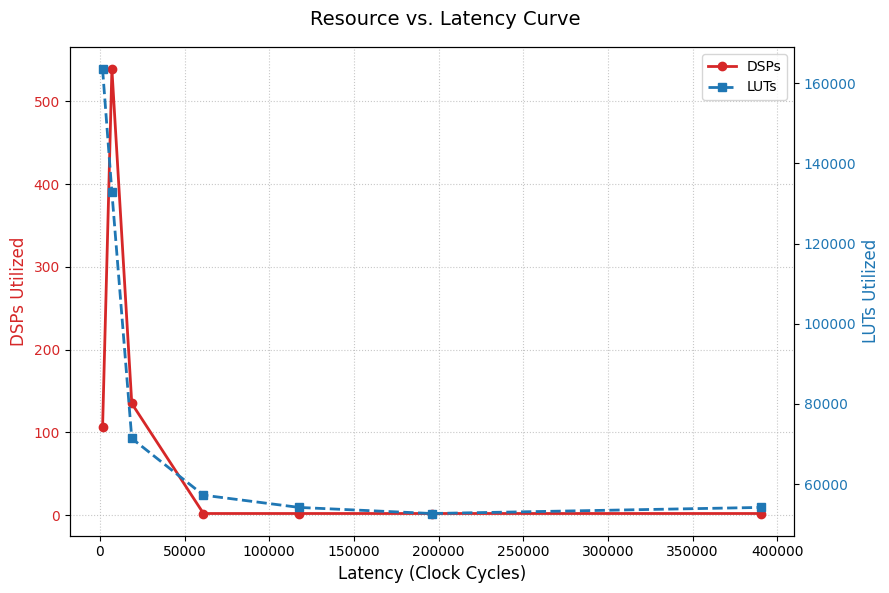

In [74]:
import matplotlib.pyplot as plt

# Extract just the RF sweep (exclude the baseline) to show the curve
golden_df = df[df.index.str.contains("Golden")].copy()

fig, ax1 = plt.subplots(figsize=(9, 6))

color = 'tab:red'
ax1.set_xlabel('Latency (Clock Cycles)', fontsize=12)
ax1.set_ylabel('DSPs Utilized', color=color, fontsize=12)
ax1.plot(golden_df["Latency (Cycles)"], golden_df["DSPs"], marker='o', color=color, linewidth=2, label="DSPs")
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle=":", alpha=0.7)

ax2 = ax1.twinx()  
color = 'tab:blue'
ax2.set_ylabel('LUTs Utilized', color=color, fontsize=12)  
ax2.plot(golden_df["Latency (Cycles)"], golden_df["LUTs"], marker='s', color=color, linewidth=2, linestyle='--', label="LUTs")
ax2.tick_params(axis='y', labelcolor=color)

# Combine the legends from both axes into one neat box in the upper right
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')

fig.suptitle('Resource vs. Latency Curve', fontsize=14) 
fig.tight_layout()  
plt.show()

In [75]:
import time
import numpy as np

golden_model = trained_models["4bit_70sparse"]

batch_sizes = [1, 8, 32, 64, 128, 256, 512, 1024, 2048, 10000]
print("\nStarting CPU Batch Size Sweep...")
print(f"{'Batch Size':>12} | {'Total Time (s)':>15} | {'Latency per Image (us)':>25} | {'Speedup over FPGA':>20}")
print("-" * 80)

fpga_latency_us = 7.94

for b in batch_sizes:
    # Warm up THIS specific batch size so TF builds the specific graph execution path
    _ = golden_model.predict(X_test[:b], batch_size=b, verbose=0)
    
    start_time = time.time()
    _ = golden_model.predict(X_test, batch_size=b, verbose=0) 
    end_time = time.time()
    
    total_time = end_time - start_time
    latency_per_image_us = (total_time / len(X_test)) * 1_000_000
    
    if latency_per_image_us < fpga_latency_us:
        speedup = f"CPU Wins ({fpga_latency_us/latency_per_image_us:.2f}x)"
    else:
        speedup = f"FPGA Wins ({latency_per_image_us/fpga_latency_us:.2f}x)"
        
    print(f"{b:>12} | {total_time:>15.4f} | {latency_per_image_us:>25.2f} | {speedup:>20}")



Starting CPU Batch Size Sweep...
  Batch Size |  Total Time (s) |    Latency per Image (us) |    Speedup over FPGA
--------------------------------------------------------------------------------
           1 |          6.9167 |                    691.67 |   FPGA Wins (87.11x)
           8 |          1.8486 |                    184.86 |   FPGA Wins (23.28x)
          32 |          1.0807 |                    108.07 |   FPGA Wins (13.61x)
          64 |          0.7790 |                     77.90 |    FPGA Wins (9.81x)
         128 |          0.6101 |                     61.01 |    FPGA Wins (7.68x)
         256 |          0.4216 |                     42.16 |    FPGA Wins (5.31x)
         512 |          0.3348 |                     33.48 |    FPGA Wins (4.22x)
        1024 |          0.3573 |                     35.73 |    FPGA Wins (4.50x)
        2048 |          0.3084 |                     30.84 |    FPGA Wins (3.88x)
       10000 |          0.2807 |                     28.07 |    F